# 02 - Saved model comparison - validation decisions, recorded final assessment

Read the existing sklearn/Spark reports. Do not retrain, rerun tuning, select a new
threshold or repeatedly assess held-out test records. Candidate ranking uses **validation
average precision (AP)**; the saved operating threshold maximizes validation churn F1.
The dummy retains its native baseline rule. Test metrics below are the previously recorded
assessment of each engine's selected model, not a new engine-selection procedure.

Validation ROC/PR curves use inference from checksum-verified sklearn candidates and saved
native Spark validation scores. No Spark JVM is needed to read these saved results.
See [required artifacts and reproduction](../../docs/NOTEBOOKS.md).

In [1]:
from pathlib import Path
import sys, json, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

here = Path.cwd().resolve()
BACKEND = next((p / "backend" if (p / "backend/config.yaml").exists() else p)
               for p in [here, *here.parents]
               if (p / "backend/config.yaml").exists() or (p / "config.yaml").exists() and (p / "src/opsyntra").exists())
sys.path.insert(0, str(BACKEND / "src"))
from opsyntra.notebook_support import Exports, verified_partition, model_reports, validation_scores, analytics_snapshot
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.prop_cycle": plt.cycler(color=["#285b46", "#a97c35", "#587b9e", "#915780", "#718d57", "#b36154", "#5c8c89"]),
                     "svg.hashsalt": "opsyntra"})
OUT = Exports(BACKEND, "02_model_comparison")
print("Export directory:", OUT.directory.relative_to(BACKEND).as_posix())

Export directory: reports/notebooks/02_model_comparison


,engine,model,selected,model_version,threshold,accuracy,average_precision,f1,precision,recall,roc_auc
0,sklearn,dummy,False,1e891f9e9fe84343,0.500000,0.734564,0.265436,0.000000,0.000000,0.000000,0.500000
1,sklearn,logistic_regression,False,f33389edebdc9cb3,0.330058,0.765791,0.650479,0.630045,0.542471,0.751337,0.837411
2,sklearn,random_forest,True,d9a13b4cf6839ed4,0.276342,0.746629,0.662603,0.635342,0.514050,0.831551,0.843368
3,sklearn,xgboost,False,f1613db4c352f815,0.375186,0.782825,0.652192,0.631325,0.574561,0.700535,0.839719
4,spark,logistic_regression,False,1de159ea821e48e4,0.334226,0.768630,0.647695,0.625287,0.548387,0.727273,0.835851
5,spark,random_forest,True,6172478f6bdcb515,0.259173,0.745209,0.661753,0.631038,0.512521,0.820856,0.842176
6,spark,xgboost,False,3eac90bb88832e08,0.375186,0.782825,0.652192,0.631325,0.574561,0.700535,0.839719


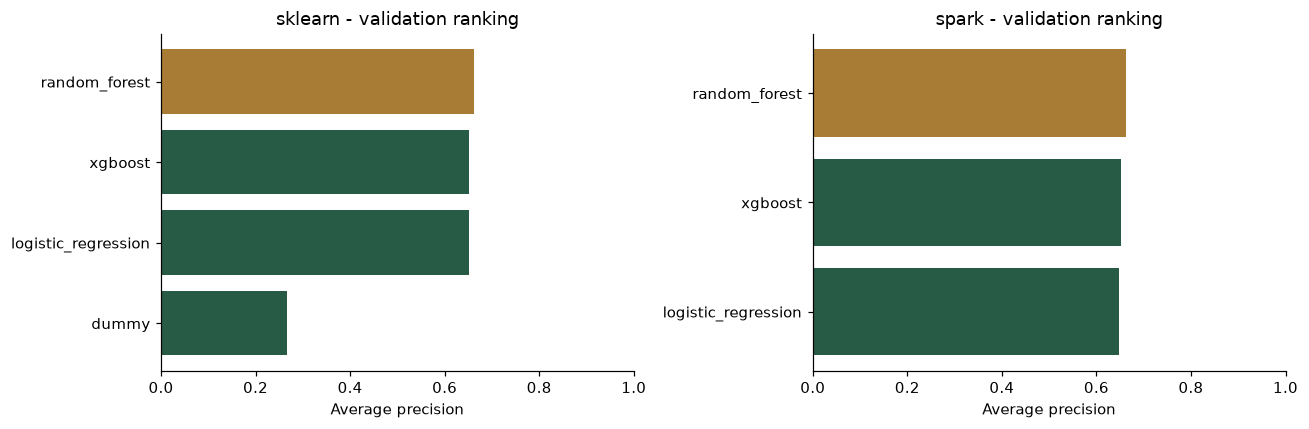

In [2]:
reports = model_reports(BACKEND, OUT)
sk, spark, comparison = reports
validation, manifest = verified_partition(BACKEND, "validation", OUT)
assert sk["provenance"]["source_sha256"] == manifest["source_sha256"]
assert sk["provenance"]["membership_sha256"] == manifest["membership_sha256"]
rows = []
for engine, report in [("sklearn",sk),("spark",spark)]:
    for name, result in report["candidates"].items():
        rows.append({"engine":engine,"model":name,"selected":name == report["selected_model"],
                     "model_version":result["model_version"],"threshold":result["decision_threshold"],
                     **{k:v for k,v in result["validation"].items() if k != "confusion_matrix"}})
metrics = pd.DataFrame(rows)
display(OUT.table("validation_comparison", metrics))
fig, axes = plt.subplots(1,2,figsize=(12,4))
for ax, engine in zip(axes,["sklearn","spark"]):
    table=metrics[metrics.engine.eq(engine)].sort_values("average_precision")
    ax.barh(table.model, table.average_precision, color=["#a97c35" if s else "#285b46" for s in table.selected])
    ax.set(title=engine+" - validation ranking",xlabel="Average precision",xlim=(0,1))
fig.tight_layout(); OUT.figure("validation_ranking",fig); plt.show()

## Saved threshold policies

Show the recorded validation-F1 search; the marker is the already selected threshold.
The notebook does not choose a new threshold. Optimizing F1 is an initial policy and is
not equivalent to minimizing business retention costs.

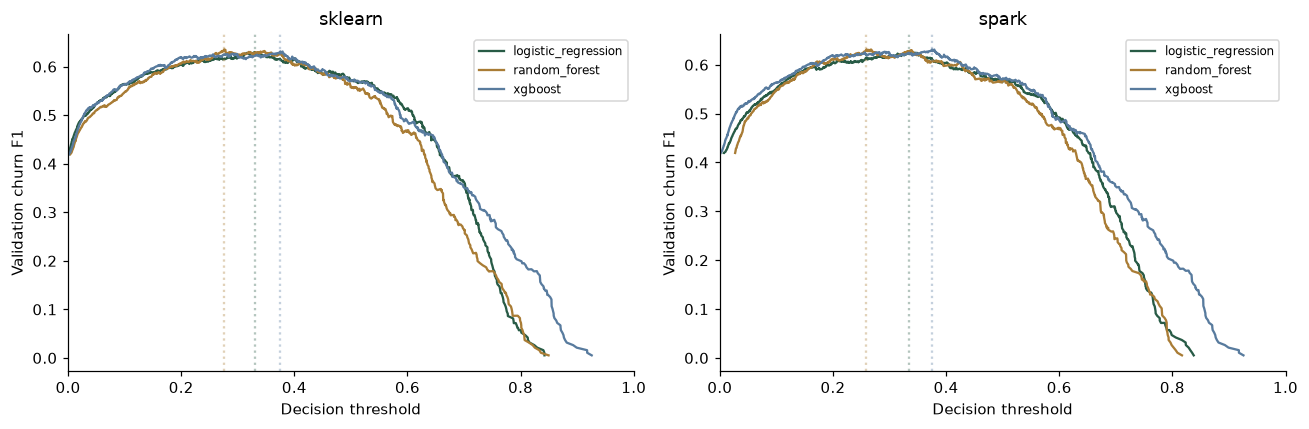

In [3]:
fig, axes = plt.subplots(1,2,figsize=(12,4))
threshold_rows=[]
for ax, (engine, report) in zip(axes,[("sklearn",sk),("spark",spark)]):
    for name, result in report["candidates"].items():
        search=result.get("threshold_selection",result.get("threshold_search",{}))
        if "thresholds" not in search: continue
        x,y=np.asarray(search["thresholds"]),np.asarray(search["f1_scores"])
        assert len(x)==len(y)
        line,=ax.plot(x,y,label=name)
        ax.axvline(result["decision_threshold"],color=line.get_color(),alpha=.35,linestyle=":")
        threshold_rows.extend({"engine":engine,"model":name,"threshold":float(a),"validation_f1":float(b)} for a,b in zip(x,y))
    ax.set(title=engine,xlabel="Decision threshold",ylabel="Validation churn F1",xlim=(0,1));ax.legend(fontsize=8)
OUT.table("recorded_threshold_search",pd.DataFrame(threshold_rows))
fig.tight_layout(); OUT.figure("validation_thresholds",fig);plt.show()

## Validation ROC and precision-recall curves

AP is the scikit-learn average-precision definition used by both engines, not trapezoidal
PR area. ROC/PR calculations here are checked against the saved validation report. Labels
and customer memberships match across engines; no held-out test feature rows are read.

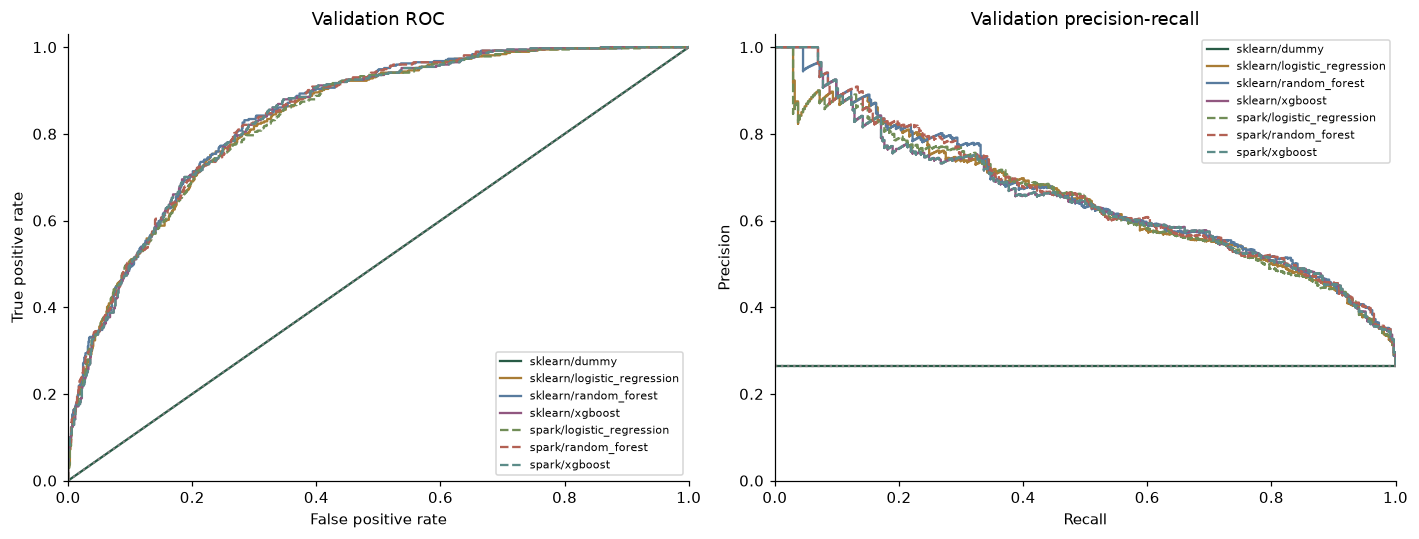

In [4]:
from sklearn.metrics import roc_curve, precision_recall_curve
scores=validation_scores(BACKEND,reports,validation,OUT)
curve_rows=[]
fig,axes=plt.subplots(1,2,figsize=(13,5))
for (engine,name),(labels,probability) in scores.items():
    label=f"{engine}/{name}"
    fpr,tpr,_=roc_curve(labels,probability)
    precision,recall,_=precision_recall_curve(labels,probability)
    style="--" if engine=="spark" else "-"
    axes[0].plot(fpr,tpr,style,label=label);axes[1].step(recall,precision,style,where="post",label=label)
    for kind,x,y in [("roc",fpr,tpr),("pr",recall,precision)]:
        curve_rows.extend({"engine":engine,"model":name,"curve":kind,"x":float(a),"y":float(b)} for a,b in zip(x,y))
axes[0].plot([0,1],[0,1],":",color="grey");axes[0].set(xlabel="False positive rate",ylabel="True positive rate",title="Validation ROC")
axes[1].axhline(validation.Churn.eq("Yes").mean(),color="grey",linestyle=":");axes[1].set(xlabel="Recall",ylabel="Precision",title="Validation precision-recall")
for ax in axes: ax.legend(fontsize=7);ax.set_xlim(0,1);ax.set_ylim(0,1.03)
OUT.table("validation_curve_points",pd.DataFrame(curve_rows))
fig.tight_layout();OUT.figure("validation_curves",fig);plt.show()

## Previously recorded final test assessment

Only each engine's already selected champion has a final test assessment. Do not use this
table to retune or pick a replacement model. Confusion matrices use actual No/Yes rows and
predicted No/Yes columns; the decision thresholds can be below 0.5.

,engine,model,model_version,threshold,accuracy,average_precision,f1,precision,recall,roc_auc
0,sklearn,random_forest,d9a13b4cf6839ed4,0.276342,0.741661,0.658023,0.620833,0.508532,0.796791,0.843857
1,spark,random_forest,6172478f6bdcb515,0.259173,0.744500,0.653868,0.623431,0.512027,0.796791,0.844087


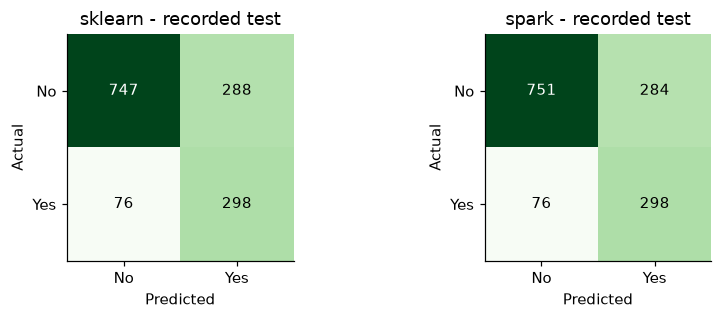

In [5]:
final=[]
fig,axes=plt.subplots(1,2,figsize=(8,3))
for ax,(engine,report) in zip(axes,[("sklearn",sk),("spark",spark)]):
    final.append({"engine":engine,"model":report["selected_model"],"model_version":report["selected_model_version"],
                  "threshold":report["decision_threshold"],**{k:v for k,v in report["selected_test_metrics"].items() if k!="confusion_matrix"}})
    matrix=np.asarray(report["selected_test_metrics"]["confusion_matrix"])
    ax.imshow(matrix,cmap="Greens");ax.set(title=engine+" - recorded test",xlabel="Predicted",ylabel="Actual",xticks=[0,1],yticks=[0,1],xticklabels=["No","Yes"],yticklabels=["No","Yes"])
    for i in range(2):
        for j in range(2):ax.text(j,i,str(matrix[i,j]),ha="center",va="center",color="white" if matrix[i,j]>matrix.max()/2 else "black")
display(OUT.table("recorded_test_assessment",pd.DataFrame(final)))
fig.tight_layout();OUT.figure("recorded_test_confusion",fig);plt.show()

## Honest timing comparison

Use the existing comparison benchmark's **single final fit** against single final fit,
not sklearn's whole grid search against one Spark fit. First inference and warmed repeats
are distinct; startup/load overhead is separate. Runtime, tuning grids, solvers and machine
size affect these results. This small local dataset does not establish distributed scaling.
The timings below are loaded measurements; this notebook performs no new training benchmark.

,engine,preprocessing_seconds,classifier_fit_seconds,fit_total_seconds,load_seconds,first_test_inference_seconds,warm_test_inference_median_seconds,spark_startup_seconds,data_load_cache_seconds
0,sklearn,0.123175,0.392384,0.515559,0.080212,0.060405,0.048739,NaN,NaN
1,spark,1.752093,8.054676,9.806769,6.628649,1.173493,1.077898,8.375075,7.221722


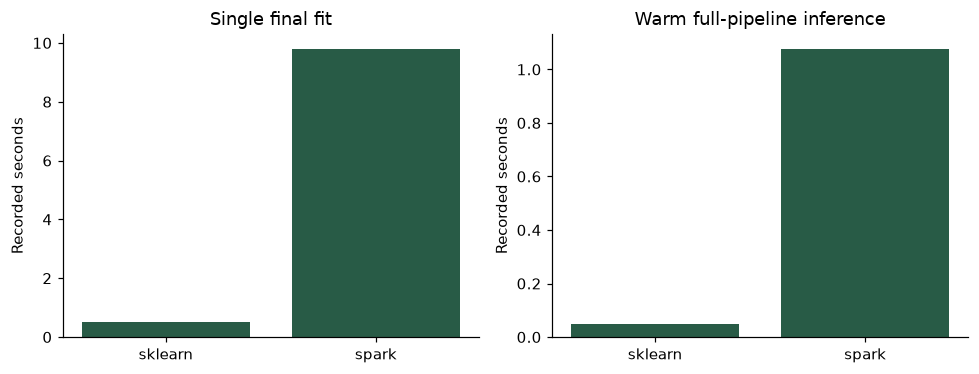

Benchmark platform: Linux-6.6.87.2-microsoft-standard-WSL2-x86_64-with-glibc2.39
- Identical saved train/validation/test customers, raw predictors, target mapping and sklearn metric definitions.
- Spark and sklearn use different solvers, regularization conventions, tree construction and tuning grids; this is a pipeline comparison, not numerical algorithm equivalence.
- Spark's exact median quantile uses an order statistic; sklearn averages middle values for even-sized samples. Spark StandardScaler uses sample standard deviation; sklearn uses population standard deviation.
- Models fit training rows only, including every CV fold's imputation and category vocabularies. Unknown categorical values map to all-zero one-hot blocks in both engines.
- Fresh sklearn final-fit timing excludes grid search. Spark final preprocessing/fit excludes its CV search, separately reported. No CV-versus-single-fit speed ratio.
- Inference uses the complete saved pipelines, raw records cached/in memory, actua

In [6]:
timing=pd.DataFrame([{"engine":e,**comparison[e]["timing"]} for e in ["sklearn","spark"]])
keep=["engine","preprocessing_seconds","classifier_fit_seconds","fit_total_seconds","load_seconds","first_test_inference_seconds","warm_test_inference_median_seconds","spark_startup_seconds","data_load_cache_seconds"]
display(OUT.table("recorded_timing",timing.reindex(columns=keep)))
fig,axes=plt.subplots(1,2,figsize=(9,3.5))
for ax,field,title in [(axes[0],"fit_total_seconds","Single final fit"),(axes[1],"warm_test_inference_median_seconds","Warm full-pipeline inference")]:
    ax.bar(timing.engine,timing[field]);ax.set(title=title,ylabel="Recorded seconds")
fig.tight_layout();OUT.figure("recorded_timing",fig);plt.show()
print("Benchmark platform:",comparison["benchmark_platform"])
for note in comparison["fairness_notes"]:print("-",note)
OUT.finish(fitted_models=0,test_feature_rows_read=0,validation_rows=len(validation),
           selection="Saved validation AP ranking and saved validation F1 threshold; not recomputed selection",
           source_sha256=manifest["source_sha256"],membership_sha256=manifest["membership_sha256"])
print("PASS: candidate validation curves agree with saved AP/ROC-AUC; final test/timing tables are recorded assessments.")